# HRNet Semantic Segmentation for SEM/Wafer Images — Dataset 1

This notebook trains a compact **HRNet (High-Resolution Network)** for binary semantic segmentation using the Roboflow COCO folder **`SEM wafer dataset-Folder- 1.coco`**.

### Dataset configuration

- Training images: **26 originals**
- Validation images: **7**
- Test images: **4**
- Training augmentation: **two independently augmented samples per original**
- Effective training samples per epoch: **26 × 3 = 78** (1 original + 2 augmented)
- Optimizer: **AdamW**
- GPU maximum epochs: **150**, with early stopping after **25** unimproved epochs

### Notebook outputs

- Training and validation loss graph
- Training and validation F1 graph
- Test pixel-level confusion matrix
- Train/Validation/Test table with Precision, Recall, Accuracy and F1 Score
- Example test predictions
- Best HRNet weights, history CSV and metrics CSV

> **F1 target:** The notebook marks 85% as a target and tunes the mask threshold using validation data only. It reports the real measured result; 85% cannot be guaranteed before training on the actual annotated images.


## Step 1 — Set up Kaggle for Dataset 1

1. Upload the complete **`SEM wafer dataset-Folder- 1.coco`** folder as a Kaggle Dataset.
2. Create a Kaggle Notebook and select **Add Input** → that uploaded dataset.
3. Open **Settings** → **Accelerator** → select **GPU T4**.
4. Import this `.ipynb` and select **Run All**.
5. If the installation cell needs downloads, enable **Internet** in notebook settings.

This notebook identifies Dataset 1 by its folder name and exact split counts: **26 train / 7 valid / 4 test**. It stops rather than silently training on the wrong folder.


In [1]:
# Kaggle usually includes these packages; this ensures the required versions are present.
!pip install -q albumentations pycocotools


## Step 2 — Imports and training configuration

The CUDA check runs an actual convolution. This catches an incompatible Kaggle GPU/PyTorch combination before training begins. A T4 is recommended; if CUDA kernels are unavailable, the notebook uses a smaller CPU-safe configuration.


In [2]:
import json, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

import albumentations as A
from pycocotools import mask as mask_utils

warnings.filterwarnings('ignore')

DATASET_NUMBER = 1
DATASET_FOLDER_HINT = 'SEM wafer dataset-Folder- 1.coco'
EXPECTED_COUNTS = {'train': 26, 'valid': 7, 'test': 4}
AUGMENTATION_COPIES = 2
SEED = 42
TARGET_F1 = 0.85
THRESHOLD_GRID = np.arange(0.20, 0.81, 0.05)
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
OUTPUT_DIR = Path('/kaggle/working/hrnet_dataset_1_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

def cuda_convolution_works():
    if not torch.cuda.is_available():
        return False, 'CUDA is not available'
    try:
        name = torch.cuda.get_device_name(0)
        capability = torch.cuda.get_device_capability(0)
        x = torch.randn(1, 3, 16, 16, device='cuda')
        weight = torch.randn(4, 3, 3, 3, device='cuda')
        F.conv2d(x, weight, padding=1).sum().item()
        del x, weight
        return True, f'{name}, compute capability {capability[0]}.{capability[1]}'
    except Exception as exc:
        return False, f'{type(exc).__name__}: {exc}'

CUDA_OK, CUDA_STATUS = cuda_convolution_works()
if CUDA_OK:
    DEVICE = torch.device('cuda')
    IMG_SIZE = 256
    BATCH_SIZE = 4
    HRNET_WIDTH = 18
    MAX_EPOCHS = 150
    EARLY_STOPPING_PATIENCE = 25
    NUM_WORKERS = 2
else:
    DEVICE = torch.device('cpu')
    IMG_SIZE = 160
    BATCH_SIZE = 2
    HRNET_WIDTH = 12
    MAX_EPOCHS = 70
    EARLY_STOPPING_PATIENCE = 14
    NUM_WORKERS = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if CUDA_OK:
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = CUDA_OK

print('Dataset:', DATASET_FOLDER_HINT)
print('Expected splits:', EXPECTED_COUNTS)
print('CUDA test:', CUDA_STATUS)
print('Selected device:', DEVICE)
if not CUDA_OK:
    print('Using CPU-safe settings. For faster training, select a Kaggle T4 GPU, restart, and Run All.')
print(f'Image={IMG_SIZE}, batch={BATCH_SIZE}, HRNet width={HRNET_WIDTH}, max epochs={MAX_EPOCHS}')


Dataset: SEM wafer dataset-Folder- 1.coco
Expected splits: {'train': 26, 'valid': 7, 'test': 4}
CUDA test: Tesla T4, compute capability 7.5
Selected device: cuda
Image=256, batch=4, HRNet width=18, max epochs=150


## Step 3 — Find and verify the COCO dataset

In a Roboflow COCO export, `_annotations.coco.json` is a file—not a directory—and the images are beside it. The code searches for a root containing `train`, `valid` and `test`, then verifies the COCO image records against files on disk.


In [3]:
def normalized_name(text):
    return ''.join(ch.lower() for ch in str(text) if ch.isalnum())

def read_coco_count(root, split):
    with open(root / split / '_annotations.coco.json', encoding='utf-8') as file:
        return len(json.load(file).get('images', []))

def find_dataset_root(search_root='/kaggle/input'):
    candidates = []
    for annotation_file in Path(search_root).rglob('_annotations.coco.json'):
        root = annotation_file.parent.parent
        if all((root / split / '_annotations.coco.json').is_file()
               for split in ('train', 'valid', 'test')):
            candidates.append(root)
    candidates = sorted(set(candidates))
    if not candidates:
        raise FileNotFoundError(
            'No train/valid/test COCO export was found under /kaggle/input. '
            f'Attach {DATASET_FOLDER_HINT} first.'
        )

    hint = normalized_name(DATASET_FOLDER_HINT)
    matches = [root for root in candidates if hint in normalized_name(root)]
    if not matches:
        matches = [root for root in candidates if all(
            read_coco_count(root, split) == expected
            for split, expected in EXPECTED_COUNTS.items()
        )]
    if len(matches) != 1:
        available = '\n'.join(str(root) for root in candidates)
        raise RuntimeError(
            f'Could not uniquely select Dataset {DATASET_NUMBER} (matches={len(matches)}). '
            f'COCO roots found:\n{available}'
        )
    return matches[0]

DATA_ROOT = find_dataset_root()
print('Selected dataset root:', DATA_ROOT)

def inspect_split(split):
    split_dir = DATA_ROOT / split
    with open(split_dir / '_annotations.coco.json', encoding='utf-8') as file:
        coco = json.load(file)
    listed = {item['file_name'] for item in coco['images']}
    disk = {path.name for path in split_dir.iterdir()
            if path.is_file() and path.suffix.lower() in {'.jpg','.jpeg','.png','.tif','.tiff'}}
    return {
        'Split key': split, 'Split': split.title(), 'COCO images': len(listed),
        'Expected images': EXPECTED_COUNTS[split], 'Image files': len(disk),
        'Annotations': len(coco.get('annotations', [])), 'Missing files': len(listed-disk)
    }

inspection = pd.DataFrame([inspect_split(split) for split in ('train','valid','test')])
display(inspection.drop(columns='Split key'))
if not (inspection['COCO images'].to_numpy() == inspection['Expected images'].to_numpy()).all():
    raise ValueError(
        f'This notebook is for Dataset {DATASET_NUMBER} with counts {EXPECTED_COUNTS}. '
        'Attach the correct dataset or correct its COCO export.'
    )
if inspection['Missing files'].sum() > 0:
    raise FileNotFoundError('Some filenames listed in COCO JSON are missing on disk.')
print('Dataset identity, split counts, and files are correct.')


Selected dataset root: /kaggle/input/datasets/hackathon07/sem-dataset-1/SEM wafer dataset-Folder- 1.coco


,Split,COCO images,Expected images,Image files,Annotations,Missing files
0,Train,26,26,26,38,0
1,Valid,7,7,7,9,0
2,Test,4,4,4,5,0


Dataset identity, split counts, and files are correct.


## Step 4 — Convert COCO annotations into masks and augment twice

All annotated categories are combined into one foreground class. Both polygon and RLE COCO formats are supported.

For every original training image, the dataset provides exactly three entries per epoch:

1. Resized original image and mask
2. First independently augmented image and mask
3. Second independently augmented image and mask

Geometric operations are applied identically to each image and its segmentation mask. Validation and test sets are resized only and are never augmented.


In [4]:
base_transform = A.Compose([A.Resize(IMG_SIZE, IMG_SIZE)])

augmentation_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Affine(scale=(0.90, 1.10), translate_percent=(-0.08, 0.08),
             rotate=(-25, 25), shear=(-5, 5), border_mode=0, p=0.65),
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=1),
        A.CLAHE(clip_limit=2.0, p=1),
        A.RandomGamma(gamma_limit=(85, 115), p=1),
    ], p=0.45),
    A.OneOf([
        A.GaussNoise(std_range=(0.01, 0.04), p=1),
        A.GaussianBlur(blur_limit=(3, 5), p=1),
    ], p=0.20),
])

class COCOSegmentationDataset(Dataset):
    def __init__(self, split, augmentation_copies=0):
        self.split = split
        self.split_dir = DATA_ROOT / split
        with open(self.split_dir / '_annotations.coco.json', encoding='utf-8') as f:
            coco = json.load(f)
        self.images = sorted(coco['images'], key=lambda item: item['id'])
        self.annotations = {}
        for ann in coco.get('annotations', []):
            self.annotations.setdefault(ann['image_id'], []).append(ann)
        self.augmentation_copies = augmentation_copies
        self.multiplier = 1 + augmentation_copies

    def __len__(self):
        return len(self.images) * self.multiplier

    @staticmethod
    def decode_annotation(annotation, height, width):
        segmentation = annotation.get('segmentation')
        if not segmentation:
            return np.zeros((height, width), dtype=np.uint8)
        if isinstance(segmentation, list):
            decoded = mask_utils.decode(mask_utils.frPyObjects(segmentation, height, width))
        elif isinstance(segmentation, dict) and isinstance(segmentation.get('counts'), list):
            decoded = mask_utils.decode(mask_utils.frPyObjects(segmentation, height, width))
        else:
            decoded = mask_utils.decode(segmentation)
        if decoded.ndim == 3:
            decoded = decoded.max(axis=2)
        return decoded.astype(np.uint8)

    def __getitem__(self, index):
        original_count = len(self.images)
        copy_number = index // original_count  # 0=original, 1/2=augmented copies
        info = self.images[index % original_count]
        image = np.asarray(Image.open(self.split_dir / info['file_name']).convert('RGB'))
        height, width = image.shape[:2]
        mask = np.zeros((height, width), dtype=np.uint8)
        for annotation in self.annotations.get(info['id'], []):
            mask = np.maximum(mask, self.decode_annotation(annotation, height, width))

        transform = augmentation_transform if copy_number > 0 else base_transform
        transformed = transform(image=image, mask=mask)
        image = transformed['image'].astype(np.float32) / 255.0
        mask = (transformed['mask'] > 0).astype(np.float32)
        image = torch.from_numpy(image.transpose(2, 0, 1))
        mask = torch.from_numpy(mask[None, ...])
        return image, mask, info['file_name'], copy_number

train_ds = COCOSegmentationDataset('train', augmentation_copies=AUGMENTATION_COPIES)
train_eval_ds = COCOSegmentationDataset('train', augmentation_copies=0)
valid_ds = COCOSegmentationDataset('valid', augmentation_copies=0)
test_ds = COCOSegmentationDataset('test', augmentation_copies=0)

loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                      pin_memory=CUDA_OK, persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_ds, shuffle=True, **loader_options)
train_eval_loader = DataLoader(train_eval_ds, shuffle=False, **loader_options)
valid_loader = DataLoader(valid_ds, shuffle=False, **loader_options)
test_loader = DataLoader(test_ds, shuffle=False, **loader_options)

print(f'{len(train_eval_ds)} original training images')
print(f'+ {len(train_eval_ds) * AUGMENTATION_COPIES} augmented samples')
print(f'= {len(train_ds)} effective training samples per epoch')
assert len(train_ds) == EXPECTED_COUNTS['train'] * (1 + AUGMENTATION_COPIES)


26 original training images
+ 52 augmented samples
= 78 effective training samples per epoch


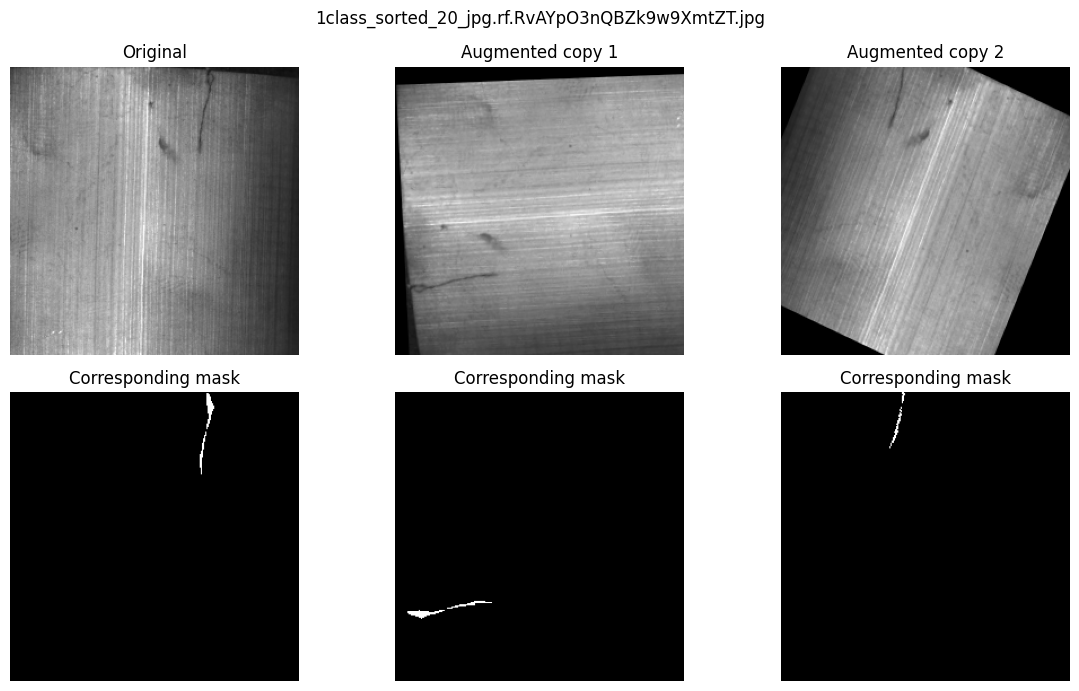

In [5]:
# Check one original and its two independently augmented versions.
sample_index = 0
indices = [sample_index + copy * len(train_eval_ds) for copy in range(3)]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for col, index in enumerate(indices):
    image, mask, filename, copy_number = train_ds[index]
    axes[0, col].imshow(image.permute(1,2,0).numpy())
    axes[0, col].set_title('Original' if copy_number == 0 else f'Augmented copy {copy_number}')
    axes[1, col].imshow(mask.squeeze().numpy(), cmap='gray')
    axes[1, col].set_title('Corresponding mask')
    axes[0, col].axis('off'); axes[1, col].axis('off')
plt.suptitle(filename)
plt.tight_layout(); plt.show()


## Step 5 — Build the HRNet segmentation model

Unlike an encoder-decoder that repeatedly discards spatial resolution, HRNet keeps a high-resolution stream throughout the network and repeatedly exchanges information with lower-resolution streams. The final head combines all four resolutions before returning a full-size binary mask.


In [6]:
class ConvBNReLU(nn.Sequential):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1):
        super().__init__(
            nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

class BasicBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = ConvBNReLU(channels, channels)
        self.conv2 = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
        )
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x):
        return self.relu(x + self.conv2(self.conv1(x)))

def make_branch(channels, blocks=2):
    return nn.Sequential(*[BasicBlock(channels) for _ in range(blocks)])

class HighResolutionModule(nn.Module):
    def __init__(self, channels, blocks=2):
        super().__init__()
        self.channels = channels
        self.branches = nn.ModuleList([make_branch(ch, blocks) for ch in channels])
        self.fuse_layers = nn.ModuleList()
        for output_index, output_ch in enumerate(channels):
            row = nn.ModuleList()
            for input_index, input_ch in enumerate(channels):
                if input_index == output_index:
                    row.append(nn.Identity())
                elif input_index > output_index:
                    row.append(nn.Sequential(
                        nn.Conv2d(input_ch, output_ch, 1, bias=False),
                        nn.BatchNorm2d(output_ch),
                    ))
                else:
                    operations = []
                    current_ch = input_ch
                    for step in range(output_index - input_index):
                        final_step = step == output_index - input_index - 1
                        next_ch = output_ch if final_step else current_ch
                        operations.extend([
                            nn.Conv2d(current_ch, next_ch, 3, stride=2, padding=1, bias=False),
                            nn.BatchNorm2d(next_ch),
                        ])
                        if not final_step:
                            operations.append(nn.ReLU(inplace=True))
                        current_ch = next_ch
                    row.append(nn.Sequential(*operations))
            self.fuse_layers.append(row)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, inputs):
        branch_outputs = [branch(x) for branch, x in zip(self.branches, inputs)]
        fused = []
        for output_index in range(len(self.channels)):
            target_size = branch_outputs[output_index].shape[-2:]
            value = None
            for input_index in range(len(self.channels)):
                contribution = self.fuse_layers[output_index][input_index](branch_outputs[input_index])
                if input_index > output_index:
                    contribution = F.interpolate(contribution, size=target_size,
                                                 mode='bilinear', align_corners=False)
                value = contribution if value is None else value + contribution
            fused.append(self.relu(value))
        return fused

class HRNetSegmentation(nn.Module):
    def __init__(self, width=18):
        super().__init__()
        self.stem = nn.Sequential(
            ConvBNReLU(3, width, stride=2),
            BasicBlock(width), BasicBlock(width),
        )
        self.transition1 = nn.ModuleList([
            nn.Identity(),
            ConvBNReLU(width, width*2, stride=2),
        ])
        self.stage2 = HighResolutionModule([width, width*2], blocks=2)
        self.transition2 = ConvBNReLU(width*2, width*4, stride=2)
        self.stage3 = nn.Sequential(
            HighResolutionModule([width, width*2, width*4], blocks=2),
            HighResolutionModule([width, width*2, width*4], blocks=2),
        )
        self.transition3 = ConvBNReLU(width*4, width*8, stride=2)
        self.stage4 = nn.Sequential(
            HighResolutionModule([width, width*2, width*4, width*8], blocks=2),
            HighResolutionModule([width, width*2, width*4, width*8], blocks=2),
        )
        combined_channels = width * (1 + 2 + 4 + 8)
        self.head = nn.Sequential(
            ConvBNReLU(combined_channels, width*4, kernel_size=1, padding=0),
            nn.Dropout2d(0.15),
            nn.Conv2d(width*4, 1, 1),
        )

    def forward(self, x):
        input_size = x.shape[-2:]
        x = self.stem(x)
        streams = [self.transition1[0](x), self.transition1[1](x)]
        streams = self.stage2(streams)
        streams = [streams[0], streams[1], self.transition2(streams[1])]
        streams = self.stage3(streams)
        streams = [streams[0], streams[1], streams[2], self.transition3(streams[2])]
        streams = self.stage4(streams)
        high_size = streams[0].shape[-2:]
        combined = torch.cat([
            streams[0],
            *[F.interpolate(stream, size=high_size, mode='bilinear', align_corners=False)
              for stream in streams[1:]]
        ], dim=1)
        return F.interpolate(self.head(combined), size=input_size,
                             mode='bilinear', align_corners=False)

model = HRNetSegmentation(width=HRNET_WIDTH).to(DEVICE)
with torch.no_grad():
    test_output = model(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
assert test_output.shape == (1, 1, IMG_SIZE, IMG_SIZE)
print(f'HRNet parameters: {sum(p.numel() for p in model.parameters()):,}')
print('Output shape test:', tuple(test_output.shape))
del test_output


HRNet parameters: 3,295,063
Output shape test: (1, 1, 256, 256)


## Step 6 — Loss, AdamW and metrics

The training objective combines weighted binary cross-entropy with Dice loss. The foreground weight is estimated from the original training masks and clipped to prevent unstable gradients. F1 is calculated globally from foreground pixel counts.


In [7]:
def estimate_positive_weight(loader):
    positive = 0.0; total = 0.0
    for _, masks, _, _ in loader:
        positive += masks.sum().item(); total += masks.numel()
    negative = total - positive
    weight = negative / max(positive, 1.0)
    return float(np.clip(weight, 1.0, 20.0)), positive / max(total, 1.0)

POS_WEIGHT, foreground_fraction = estimate_positive_weight(train_eval_loader)
print(f'Foreground pixels: {foreground_fraction:.3%}; BCE positive weight: {POS_WEIGHT:.2f}')

bce_loss = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([POS_WEIGHT], device=DEVICE))

def dice_loss(logits, targets, eps=1e-7):
    probabilities = torch.sigmoid(logits)
    intersection = (probabilities * targets).sum(dim=(1,2,3))
    denominator = probabilities.sum(dim=(1,2,3)) + targets.sum(dim=(1,2,3))
    return 1 - ((2 * intersection + eps) / (denominator + eps)).mean()

def combined_loss(logits, targets):
    return 0.5 * bce_loss(logits, targets) + 0.5 * dice_loss(logits, targets)

def confusion_counts(logits, targets, threshold=0.5):
    predicted = torch.sigmoid(logits) >= threshold
    actual = targets >= 0.5
    tp = (predicted & actual).sum().item()
    fp = (predicted & ~actual).sum().item()
    fn = (~predicted & actual).sum().item()
    tn = (~predicted & ~actual).sum().item()
    return np.array([tp, fp, fn, tn], dtype=np.float64)

def metrics_from_counts(counts, eps=1e-8):
    tp, fp, fn, tn = counts
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    accuracy = (tp + tn) / (tp + fp + fn + tn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)
    return precision, recall, accuracy, f1


Foreground pixels: 0.427%; BCE positive weight: 20.00


## Step 7 — Train HRNet

AdamW updates the network, `ReduceLROnPlateau` lowers the learning rate when validation F1 stops improving, and early stopping restores the checkpoint with the highest validation F1. The epoch count is a maximum—not a requirement to overtrain.


In [8]:
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5)
scaler = torch.amp.GradScaler('cuda', enabled=CUDA_OK)

history = {'train_loss': [], 'valid_loss': [], 'train_f1': [], 'valid_f1': [], 'learning_rate': []}
best_validation_f1 = -1.0
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    running_loss = 0.0
    train_counts = np.zeros(4, dtype=np.float64)
    for images, masks, _, _ in train_loader:
        images = images.to(DEVICE, non_blocking=CUDA_OK)
        masks = masks.to(DEVICE, non_blocking=CUDA_OK)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type='cuda', enabled=CUDA_OK):
            logits = model(images)
            loss = combined_loss(logits, masks)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * images.size(0)
        train_counts += confusion_counts(logits.detach(), masks)

    train_loss_value = running_loss / len(train_loader.dataset)
    train_f1_value = metrics_from_counts(train_counts)[3]

    model.eval()
    running_loss = 0.0
    valid_counts = np.zeros(4, dtype=np.float64)
    with torch.no_grad():
        for images, masks, _, _ in valid_loader:
            images = images.to(DEVICE, non_blocking=CUDA_OK)
            masks = masks.to(DEVICE, non_blocking=CUDA_OK)
            logits = model(images)
            loss = combined_loss(logits, masks)
            running_loss += loss.item() * images.size(0)
            valid_counts += confusion_counts(logits, masks)

    valid_loss_value = running_loss / len(valid_loader.dataset)
    valid_f1_value = metrics_from_counts(valid_counts)[3]
    scheduler.step(valid_f1_value)

    history['train_loss'].append(train_loss_value)
    history['valid_loss'].append(valid_loss_value)
    history['train_f1'].append(train_f1_value)
    history['valid_f1'].append(valid_f1_value)
    history['learning_rate'].append(optimizer.param_groups[0]['lr'])

    print(f'Epoch {epoch:03d}/{MAX_EPOCHS} | '
          f'Loss train={train_loss_value:.4f}, valid={valid_loss_value:.4f} | '
          f'F1 train={train_f1_value:.4f}, valid={valid_f1_value:.4f} | '
          f'LR={optimizer.param_groups[0]["lr"]:.2e}')

    if valid_f1_value > best_validation_f1 + 1e-4:
        best_validation_f1 = valid_f1_value
        epochs_without_improvement = 0
        torch.save(model.state_dict(), OUTPUT_DIR / 'best_hrnet_dataset_1.pth')
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print('Early stopping: validation F1 did not improve.')
            break

pd.DataFrame(history).to_csv(OUTPUT_DIR / 'hrnet_dataset_1_training_history.csv', index=False)
model.load_state_dict(torch.load(OUTPUT_DIR / 'best_hrnet_dataset_1.pth', map_location=DEVICE))
print(f'Best validation F1 at threshold 0.50: {best_validation_f1:.4f}')


Epoch 001/150 | Loss train=0.7695, valid=0.6842 | F1 train=0.0169, valid=0.0000 | LR=3.00e-04
Epoch 002/150 | Loss train=0.7042, valid=0.6686 | F1 train=0.0502, valid=0.0166 | LR=3.00e-04
Epoch 003/150 | Loss train=0.6730, valid=0.6487 | F1 train=0.1033, valid=0.1649 | LR=3.00e-04
Epoch 004/150 | Loss train=0.6421, valid=0.6219 | F1 train=0.1699, valid=0.3534 | LR=3.00e-04
Epoch 005/150 | Loss train=0.6238, valid=0.6078 | F1 train=0.1749, valid=0.2244 | LR=3.00e-04
Epoch 006/150 | Loss train=0.6070, valid=0.6047 | F1 train=0.2227, valid=0.2343 | LR=3.00e-04
Epoch 007/150 | Loss train=0.5907, valid=0.5779 | F1 train=0.2536, valid=0.1709 | LR=3.00e-04
Epoch 008/150 | Loss train=0.5780, valid=0.5606 | F1 train=0.2789, valid=0.3387 | LR=3.00e-04
Epoch 009/150 | Loss train=0.5625, valid=0.5578 | F1 train=0.2795, valid=0.3072 | LR=3.00e-04
Epoch 010/150 | Loss train=0.5613, valid=0.5393 | F1 train=0.2700, valid=0.4632 | LR=3.00e-04
Epoch 011/150 | Loss train=0.5544, valid=0.5268 | F1 train=0

## Step 8 — Plot loss and F1 graphs

If training loss keeps falling while validation loss rises, the model is overfitting. The green line shows the requested 85% F1 target.


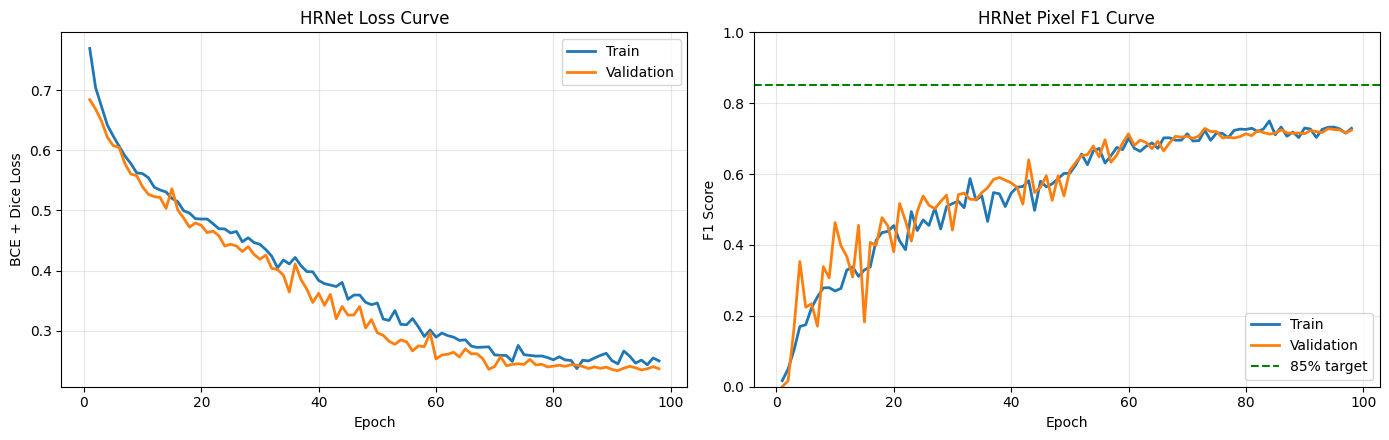

In [9]:
epochs_completed = np.arange(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(epochs_completed, history['train_loss'], label='Train', linewidth=2)
axes[0].plot(epochs_completed, history['valid_loss'], label='Validation', linewidth=2)
axes[0].set_title('HRNet Loss Curve'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE + Dice Loss')
axes[0].grid(alpha=0.3); axes[0].legend()

axes[1].plot(epochs_completed, history['train_f1'], label='Train', linewidth=2)
axes[1].plot(epochs_completed, history['valid_f1'], label='Validation', linewidth=2)
axes[1].axhline(TARGET_F1, color='green', linestyle='--', label='85% target')
axes[1].set_title('HRNet Pixel F1 Curve'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('F1 Score')
axes[1].set_ylim(0, 1); axes[1].grid(alpha=0.3); axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'hrnet_dataset_1_loss_and_f1_curves.png', dpi=180, bbox_inches='tight')
plt.show()


## Step 9 — Select the probability threshold using validation data

The best threshold is chosen only from validation images. It is then frozen before test evaluation. This improves the decision boundary without leaking information from the test set.


In [10]:
@torch.no_grad()
def collect_pixels(loader):
    model.eval()
    probability_parts, truth_parts = [], []
    for images, masks, _, _ in loader:
        probabilities = torch.sigmoid(model(images.to(DEVICE))).cpu().numpy().ravel()
        probability_parts.append(probabilities)
        truth_parts.append(masks.numpy().ravel().astype(np.uint8))
    return np.concatenate(probability_parts), np.concatenate(truth_parts)

validation_probabilities, validation_truth = collect_pixels(valid_loader)
threshold_results = []
for threshold in THRESHOLD_GRID:
    predicted = validation_probabilities >= threshold
    actual = validation_truth == 1
    counts = np.array([
        np.sum(predicted & actual), np.sum(predicted & ~actual),
        np.sum(~predicted & actual), np.sum(~predicted & ~actual)
    ], dtype=np.float64)
    precision, recall, accuracy, f1 = metrics_from_counts(counts)
    threshold_results.append([threshold, precision, recall, accuracy, f1])

threshold_table = pd.DataFrame(threshold_results,
    columns=['Threshold', 'Precision', 'Recall', 'Accuracy', 'F1 Score'])
BEST_THRESHOLD = float(threshold_table.loc[threshold_table['F1 Score'].idxmax(), 'Threshold'])
display(threshold_table.style.format('{:.4f}').hide(axis='index'))
print(f'Selected threshold: {BEST_THRESHOLD:.2f}')


Threshold,Precision,Recall,Accuracy,F1 Score
0.2000,0.5819,0.8270,0.9975,0.6831
0.2500,0.5979,0.8216,0.9976,0.6921
0.3000,0.6131,0.8129,0.9977,0.6990
0.3500,0.6319,0.8048,0.9978,0.7080
0.4000,0.6551,0.7975,0.9980,0.7193
0.4500,0.6727,0.7914,0.9981,0.7273
0.5000,0.6856,0.7780,0.9981,0.7289
0.5500,0.6948,0.7619,0.9981,0.7268
0.6000,0.7082,0.7471,0.9982,0.7272
0.6500,0.7182,0.7317,0.9982,0.7249


Selected threshold: 0.50


## Step 10 — Train/Validation/Test comparison table

These are global **pixel-level** binary segmentation metrics. Accuracy includes the usually dominant background class, so F1, precision and recall should be interpreted alongside it.


In [11]:
@torch.no_grad()
def evaluate_split(loader, threshold):
    model.eval()
    counts = np.zeros(4, dtype=np.float64)
    for images, masks, _, _ in loader:
        logits = model(images.to(DEVICE))
        counts += confusion_counts(logits, masks.to(DEVICE), threshold)
    precision, recall, accuracy, f1 = metrics_from_counts(counts)
    return {
        'Precision': precision, 'Recall': recall,
        'Accuracy': accuracy, 'F1 Score': f1
    }, counts

comparison_rows = []
all_counts = {}
for split_name, loader in [('Train', train_eval_loader), ('Validation', valid_loader), ('Test', test_loader)]:
    result, counts = evaluate_split(loader, BEST_THRESHOLD)
    comparison_rows.append({'Dataset': split_name, **result})
    all_counts[split_name] = counts

comparison_table = pd.DataFrame(comparison_rows)
comparison_table.to_csv(OUTPUT_DIR / 'hrnet_dataset_1_metrics_comparison.csv', index=False)
display(comparison_table.style.format({
    'Precision': '{:.4f}', 'Recall': '{:.4f}',
    'Accuracy': '{:.4f}', 'F1 Score': '{:.4f}'
}).hide(axis='index'))

test_f1 = float(comparison_table.loc[comparison_table['Dataset']=='Test', 'F1 Score'].iloc[0])
if test_f1 >= TARGET_F1:
    print(f'85% target reached: test F1 = {test_f1:.2%}')
else:
    print(f'Test F1 = {test_f1:.2%}. The 85% target was not reached; do not replace this measured result.')


Dataset,Precision,Recall,Accuracy,F1 Score
Train,0.7712,0.9571,0.9986,0.8542
Validation,0.6856,0.7780,0.9981,0.7289
Test,0.6711,0.8343,0.9992,0.7438


Test F1 = 74.38%. The 85% target was not reached; do not replace this measured result.


## Step 11 — Test confusion matrix

Rows represent actual pixels and columns represent predicted pixels. Each cell shows both the pixel count and row-normalized percentage.


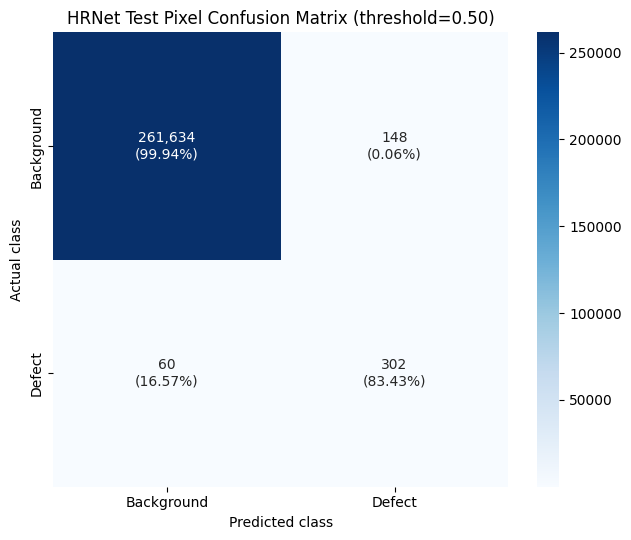

In [12]:
tp, fp, fn, tn = all_counts['Test'].astype(np.int64)
confusion = np.array([[tn, fp], [fn, tp]], dtype=np.int64)
row_percent = confusion / np.maximum(confusion.sum(axis=1, keepdims=True), 1)
annotations = np.array([
    [f'{confusion[row,col]:,}\n({row_percent[row,col]:.2%})' for col in range(2)]
    for row in range(2)
])

plt.figure(figsize=(6.5, 5.5))
sns.heatmap(confusion, annot=annotations, fmt='', cmap='Blues', cbar=True,
            xticklabels=['Background', 'Defect'], yticklabels=['Background', 'Defect'])
plt.xlabel('Predicted class'); plt.ylabel('Actual class')
plt.title(f'HRNet Test Pixel Confusion Matrix (threshold={BEST_THRESHOLD:.2f})')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'hrnet_dataset_1_test_confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()


## Step 12 — Inspect test predictions

Reviewing images is essential: aggregate metrics may hide missed small defects, boundary errors or false positives caused by wafer texture.


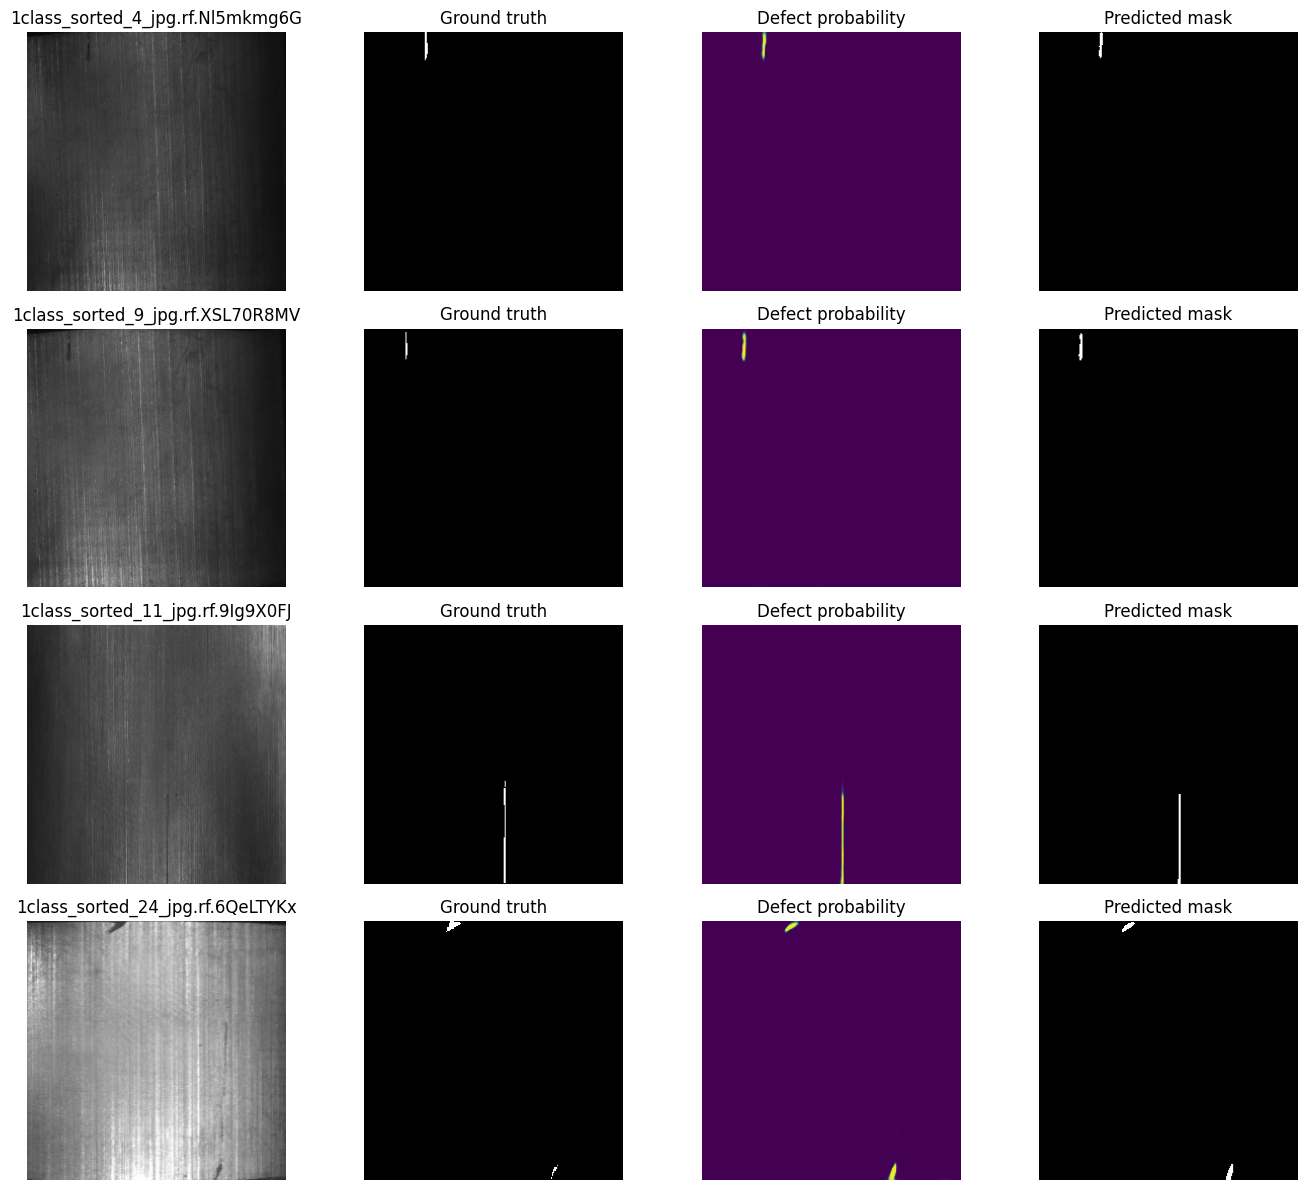

In [13]:
@torch.no_grad()
def show_predictions(dataset, number_to_show=6):
    model.eval()
    number_to_show = min(number_to_show, len(dataset))
    indices = np.linspace(0, len(dataset)-1, number_to_show, dtype=int)
    fig, axes = plt.subplots(number_to_show, 4, figsize=(14, 3*number_to_show), squeeze=False)
    for row, index in enumerate(indices):
        image, mask, filename, _ = dataset[index]
        probability = torch.sigmoid(model(image.unsqueeze(0).to(DEVICE)))[0,0].cpu().numpy()
        prediction = probability >= BEST_THRESHOLD
        panels = [image.permute(1,2,0).numpy(), mask[0].numpy(), probability, prediction]
        titles = [filename[:32], 'Ground truth', 'Defect probability', 'Predicted mask']
        cmaps = [None, 'gray', 'viridis', 'gray']
        for col in range(4):
            axes[row,col].imshow(panels[col], cmap=cmaps[col])
            axes[row,col].set_title(titles[col]); axes[row,col].axis('off')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'hrnet_dataset_1_test_predictions.png', dpi=180, bbox_inches='tight')
    plt.show()

show_predictions(test_ds)


## Step 13 — Download the outputs

After **Run All** finishes, open Kaggle's **Output** panel and download the folder:

`/kaggle/working/hrnet_dataset_1_outputs`

It contains:

- `best_hrnet_dataset_1.pth`
- `hrnet_dataset_1_training_history.csv`
- `hrnet_dataset_1_loss_and_f1_curves.png`
- `hrnet_dataset_1_metrics_comparison.csv`
- `hrnet_dataset_1_test_confusion_matrix.png`
- `hrnet_dataset_1_test_predictions.png`

### If F1 remains below 85%

1. Visually verify that every COCO mask aligns with its SEM image.
2. Increase `IMG_SIZE` to 384 if defects are very small and GPU memory permits.
3. Examine whether false negatives or false positives dominate the confusion matrix.
4. With only 67 training images, collect more annotated wafers or use cross-validation.
5. Do not tune hyperparameters on the nine test images; use validation data only.
